# Task 62: Performance Stability Across Splits

Repeat random and stratified holdouts, manually train the same logistic model, and compare metric variability and class composition.

Twenty-seed repeated holdout summary:


accuracy                      precision                       \
               mean    std    min    max      mean    std    min    max   
split                                                                     
random        0.827  0.045  0.767  0.900     0.798  0.077  0.655  0.971   
stratified    0.825  0.035  0.754  0.902     0.805  0.038  0.738  0.886   

           recall                         f1                       \
             mean    std    min   max   mean    std    min    max   
split                                                               
random      0.900  0.054  0.794  0.97  0.843  0.046  0.731  0.917   
stratified  0.897  0.049  0.818  0.97  0.847  0.030  0.783  0.912   

           test positive rate                       
                         mean    std    min    max  
split                                               
random                  0.524  0.059  0.383  0.633  
stratified              0.541  0.000  0.541  0.541

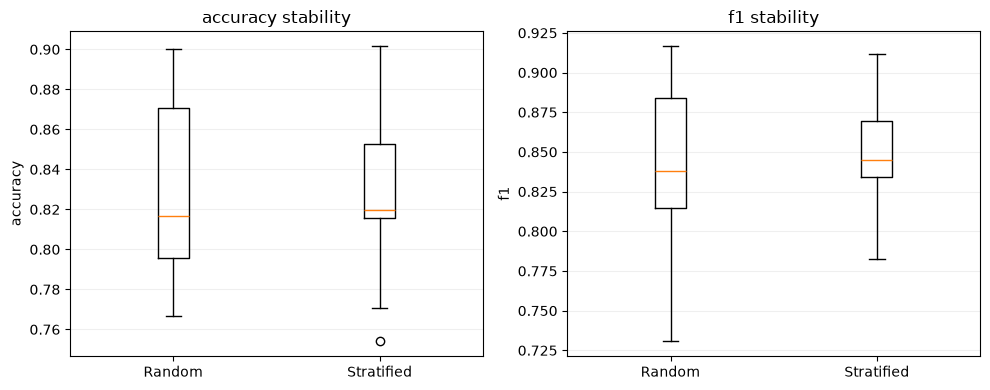

Stratification stabilizes label proportions but does not eliminate variability from which examples are held out. Repeated folds reuse observations, so the standard deviations are descriptive rather than independent confidence intervals.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

paths=[Path('heart.csv'),Path('Task_62_Split_Stability_Analysis/heart.csv'),Path('Heart_Disease_Tasks/Task_62_Split_Stability_Analysis/heart.csv')]
data=pd.read_csv(next(p for p in paths if p.is_file())).drop_duplicates().reset_index(drop=True)
features=[c for c in ['age','sex','cp','trestbps','chol','fbs','restecg','thalach','exang','oldpeak','slope','ca','thal'] if c in data]
X,y=data[features].to_numpy(float),data.target.to_numpy(int)

def split_indices(labels,test_fraction,seed,stratified):
    rng=np.random.default_rng(seed)
    if not stratified:
        indices=rng.permutation(len(labels));cut=int(round(len(labels)*(1-test_fraction)))
        return indices[:cut],indices[cut:]
    train_parts=[];test_parts=[]
    for label in np.unique(labels):
        indices=np.flatnonzero(labels==label);rng.shuffle(indices);cut=int(round(len(indices)*(1-test_fraction)))
        train_parts.append(indices[:cut]);test_parts.append(indices[cut:])
    train=np.concatenate(train_parts);test=np.concatenate(test_parts);rng.shuffle(train);rng.shuffle(test)
    return train,test

class ManualLogistic:
    def fit(self,x,y,rate=.06,steps=1000,l2=.02):
        self.w=np.zeros(x.shape[1]);self.b=0.
        for _ in range(steps):
            p=1/(1+np.exp(-np.clip(x@self.w+self.b,-35,35)));e=p-y
            self.w-=rate*(x.T@e/len(y)+l2*self.w);self.b-=rate*e.mean()
        return self
    def predict(self,x):return (1/(1+np.exp(-np.clip(x@self.w+self.b,-35,35)))>=.5).astype(int)
def measure(actual,pred):
    tp=np.sum((actual==1)&(pred==1));tn=np.sum((actual==0)&(pred==0));fp=np.sum((actual==0)&(pred==1));fn=np.sum((actual==1)&(pred==0))
    precision=tp/(tp+fp) if tp+fp else 0.;recall=tp/(tp+fn) if tp+fn else 0.
    return {'accuracy':(tp+tn)/len(actual),'precision':precision,'recall':recall,'f1':2*precision*recall/(precision+recall) if precision+recall else 0.}

records=[]
for split_type in ['random','stratified']:
    for seed in range(20):
        train,test=split_indices(y,.2,6200+seed,split_type=='stratified')
        xtr,xte=X[train],X[test];ytr,yte=y[train],y[test]
        mean,scale=xtr.mean(0),xtr.std(0);scale[scale==0]=1;xtr,xte=(xtr-mean)/scale,(xte-mean)/scale
        model=ManualLogistic().fit(xtr,ytr);score=measure(yte,model.predict(xte))
        records.append({'split':split_type,'seed':seed,**score,'test positive rate':float(yte.mean())})
results=pd.DataFrame(records)
summary=results.groupby('split')[['accuracy','precision','recall','f1','test positive rate']].agg(['mean','std','min','max'])
print('Twenty-seed repeated holdout summary:');display(summary.round(3))
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,metric in zip(axes,['accuracy','f1']):
    ax.boxplot([results.loc[results.split=='random',metric],results.loc[results.split=='stratified',metric]],tick_labels=['Random','Stratified'])
    ax.set_ylabel(metric);ax.set_title(f'{metric} stability');ax.grid(axis='y',alpha=.2)
plt.tight_layout();plt.show()
print('Stratification stabilizes label proportions but does not eliminate variability from which examples are held out. Repeated folds reuse observations, so the standard deviations are descriptive rather than independent confidence intervals.')